In [2]:
import pandas as pd
import numpy as np

import scipy.io as sio
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
from scipy.stats import gaussian_kde

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [3]:
def getTrialAlignment(index, unittp):
    repeats = []
    for idx_st, idx_stop in zip(index['index_starts'], index['index_stops']):
        rep = unittp[(unittp > idx_st) & (unittp < idx_stop)].values
        rep = rep - idx_st
        repeats.append([rep])
    return repeats

In [4]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds

In [5]:
# read in the timestamps
name = 'm31_wn2'
import pickle
filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_timeStamps.pickle'
with open(filename, "rb") as f:
    testout = pickle.load(f)
all_Units_aligned = testout[0]
all_Units_prior = testout[1]
WhiteNoise = testout[2]

In [6]:
index = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/' + name + '_index.csv')
index_tp = index * 1/Fs
index_tp

,index_starts,index_stops
0,1.042433,11.042533
1,13.106333,23.106400
2,25.170200,35.170300
3,37.234100,47.234167
4,49.297967,59.298067
5,61.361867,71.361933
6,73.425733,83.425833
7,85.489633,95.489700
8,97.553500,107.553600
9,109.617400,119.617467


In [7]:
data = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/' + name + '_degrees.csv')
Stim = data['angle_degrees']
# Nerve = data['amplifier_channel_sorted']

In [8]:
data.head()

,scaled_voltage,displacement_cm,angle_degrees
0,-0.435486,0.048555,3.967961
1,-0.430603,0.047981,3.921175
2,-0.427246,0.047586,3.889007
3,-0.439453,0.049022,4.005971
4,-0.432892,0.048250,3.943107


In [9]:
# get the first WN repeat 
start = index.loc[0, :][0]
stop = index.loc[0, :][1]
WhiteNoise = Stim[start:stop]

/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/750754063.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  start = index.loc[0, :][0]
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/750754063.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  stop = index.loc[0, :][1]


In [10]:
for k in all_Units_aligned.keys():
    f = plt.figure(figsize=(20,10))
    axes = f.add_axes([0.1, 0.8, 1, 0.2])
    axes2 = f.add_axes([0.1, 0, 1, 0.75])
    
    print(len(np.concatenate(all_Units_aligned[k])))

    #can plot here just for raster plot & stim figure- or run last cell to get combined stim, raster, PSTH plot
    
    axes.plot(np.arange(0,len(WhiteNoise))*1/Fs, WhiteNoise
              , color = 'black'
              , linewidth = 1
             )
    axes.set_xticklabels([])
    axes.set_ylabel('Proboscis Movement (Degrees)', fontsize = 15)
    
    axes2.eventplot(all_Units_aligned[k]
                  ,linelengths = 0.5
                 ,lineoffsets = 1
                 , linewidth = 1
                 , color = 'black'
                   )
    axes2.set_xlim([0, len(WhiteNoise)*1/Fs])
    axes.set_xlim([0, len(WhiteNoise)*1/Fs])
    axes2.set_ylabel('Repeats', fontsize = 15)
    axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
    axes2.set_xlabel('Time (seconds)', fontsize = 15)
    axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)
    stim_min = round(WhiteNoise.min(), 1)
    stim_max = round(WhiteNoise.max(), 1)
    axes.set_yticks([stim_min, 0, stim_max])
    axes.set_yticklabels([stim_min, 0, stim_max], fontsize=10)
    
    raster_data = []
    for repeat_idx, spikes in enumerate(all_Units_aligned[k]):
        for spike_time in np.atleast_1d(np.array(spikes).flatten()):  
            raster_data.append({'repeat': repeat_idx + 1, 'spike_time': spike_time})
    raster_df = pd.DataFrame(raster_data)
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_newraster.csv'
    raster_df.to_csv(filename, index=False)
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_newraster.pdf'


    
    #plt.savefig(filename, bbox_inches='tight')
    #plt.show()
    #plt.close(f)

12296
6640
2333
923


/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/4131892258.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/4131892258.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_xticklabels(labels = axes2.get_xticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/4131892258.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes2.set_yticklabels(labels = axes2.get_yticks(), fontsize = 10)
/var/folders/__/mwz7g0652137ypy1vqmvdp3c0000gn/T/ipykernel_23078/4131892258.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, 

In [11]:
# save aligned spikes and whiteNoise repeat separately 

# whiteNoise_single = pd.DataFrame({'WhiteNoise': WhiteNoise})
# Unit1 = pd.DataFrame({'repeats_unit1': Spike_repeats_unit1})
# Unit2 = pd.DataFrame({'repeats_unit2': Spike_repeats_unit2})

In [13]:
#create the PSTH aligning to the raster plot here 
unit_name = "unit_2" #loop around all units if i want instead of individually 

bin_size = 0.1 
stim_duration = 10.0 #duration of one repeat

raster = all_Units_aligned[unit_name] # extract all the spike and unit data from the raster
num_repeats = len(raster) 
spikes = np.concatenate(raster)
edges = np.arange(0, stim_duration + bin_size, bin_size)
counts, _ = np.histogram(spikes, bins=edges)
psth = counts / (num_repeats * bin_size) #takes the count which is total no. of spikes and converts to firing rate (spikes/second)

#plot the PSTH with Gaussian KDE on the same axis 
fig, ax1 = plt.subplots(figsize=(20, 3.75))
ax2 = ax1.twinx()

ax1.bar(
    edges[:-1],
    psth,
    width=bin_size,
    align="edge",
    edgecolor="black",
    color="0.3")

kde = gaussian_kde(edges[:-1], weights=psth, bw_method=0.06)
x_grid = np.linspace(edges[:-1].min(), edges[-1].max(), 1000)
density = kde(x_grid)
ax2.plot(x_grid, density, color="blue", linewidth=2.5)

ax1.set_xlim(0, stim_duration)
ax1.set_xlabel("Time (s)", fontsize=15)
ax1.set_ylabel("Firing rate", fontsize=15)
ax1.tick_params(axis='both', labelsize=10)

ax2.set_ylabel("KDE Value", fontsize=15, color="blue")
ax2.tick_params(axis='y', labelsize=10, labelcolor="blue")

plt.tight_layout()

#save_path = ("/Users/meghnaanand/Desktop/Analysis/"+ name + "_" + unit_name + "_PSTH.pdf")
#plt.savefig(save_path, bbox_inches="tight")
#plt.show()

full_data_df = pd.DataFrame({
    'time': x_grid,
    'kde': density})
save_path = (f"/Users/meghnaanand/Desktop/Analysis/"f"{name}_{unit_name}_fullgaussiankde.csv")
full_data_df.to_csv(save_path, index=False)

kde_at_bins = kde(edges[:-1]) #matches the kde values aligning bin values as opposed to all points for comparison
full_data_df = pd.DataFrame({
    'time': edges[:-1],
    'psth': psth,
    'kde': kde_at_bins})
save_path = (f"/Users/meghnaanand/Desktop/Analysis/"f"{name}_{unit_name}_PSTH_data.csv")
full_data_df.to_csv(save_path, index=False)

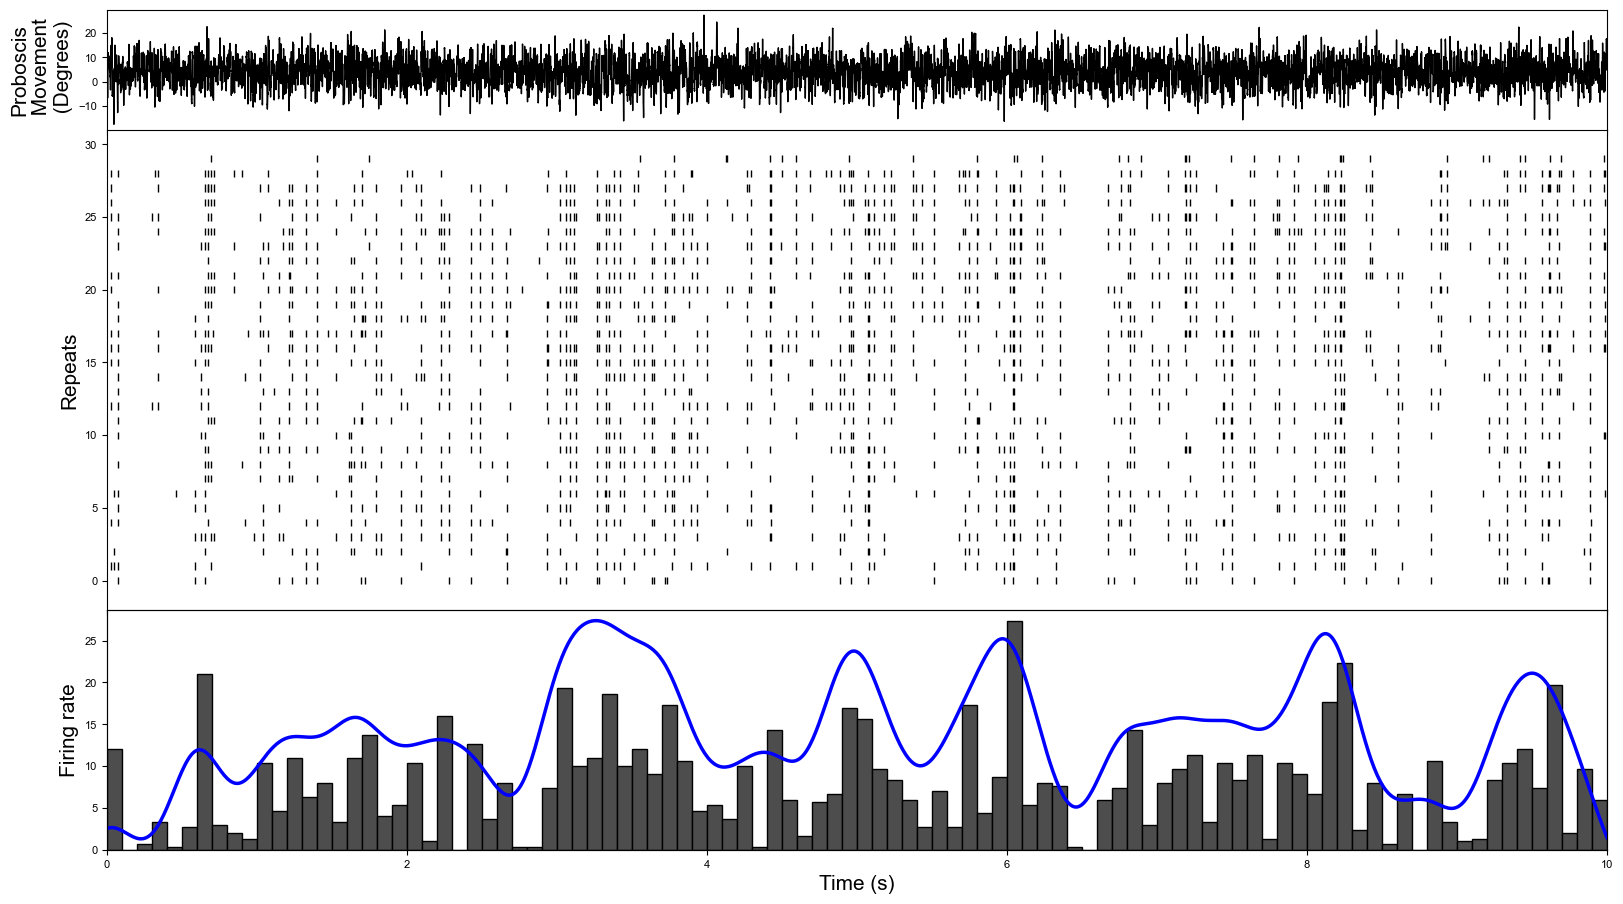

In [18]:
#make subplot with shared x axis here for figure
#adjust fig ratio as wanted for paper

k = 'unit_2'

fig, (ax_stim, ax_raster, ax_psth) = plt.subplots(3, 1, figsize=(20, 10), sharex=True, gridspec_kw={'height_ratios': [0.5, 2, 1], 'hspace': 0})

ax_stim.plot(np.arange(0, len(WhiteNoise)) * 1/Fs, WhiteNoise, color='black', linewidth=1)
ax_stim.set_ylabel('Proboscis\n Movement\n (Degrees)', fontsize=15)
ax_stim.spines['bottom'].set_visible(False)
ax_raster.eventplot(all_Units_aligned[k], linelengths=0.5, lineoffsets=1, linewidth=1, color='black')
ax_raster.set_ylabel('Repeats', fontsize=15)
ax_raster.spines['bottom'].set_visible(False)
ax_psth.bar(edges[:-1], psth, width=bin_size, align='edge', edgecolor='black', color='0.3')
ax_psth.set_ylabel('Firing rate', fontsize=15)
ax_psth.set_xlabel('Time (s)', fontsize=15)
ax_psth2 = ax_psth.twinx()
ax_psth2.plot(x_grid, density, color='blue', linewidth=2.5)
ax_psth2.set_yticks([])

ax_stim.margins(x=0)
ax_raster.margins(x=0)
ax_psth.margins(x=0)

plt.subplots_adjust(left=0.15, top=0.95)

#plt.savefig(f'/Users/meghnaanand/Desktop/{name}_{k}_combined.pdf', bbox_inches='tight')
plt.show()